# Phân tích nghỉ việc nhân sự — IBM HR Analytics Employee Attrition & Performance
**Mid-term 2 – Project 5 | Khoa học dữ liệu trong kinh tế và kinh doanh (NEU)**

Nhóm: Nguyễn Thu Trang (11248108), Hoàng Minh Ngọc (11247707), Tạ Bùi Vân Anh (11244614), Nguyễn Hoàng Hà Anh (11242469), Nguyễn Quang Huy

GitHub: https://github.com/trangthu171106/ibm-hr-attrition-analysis

**Câu hỏi kinh doanh:** Nhân viên nào có nguy cơ nghỉ việc, vì sao, và doanh nghiệp nên can thiệp ở đâu để giảm chi phí nghỉ việc?

Notebook đi theo 4 giai đoạn của đề bài:
1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích, kiểm định giả thuyết, trực quan hóa (+ mô hình dự báo rủi ro)
4. Đánh giá tác động và khuyến nghị

> Chạy được bằng **Runtime → Run all** trên Google Colab. Dữ liệu tự tải từ kho GitHub chính thức của IBM nếu không có file cục bộ.

In [1]:
# ============================================================
# 0. THIẾT LẬP MÔI TRƯỜNG: thư viện, bảng màu, hàm tiện ích
# ============================================================
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report, recall_score, precision_score, f1_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Bảng màu đã kiểm tra an toàn cho người mù màu: xanh = Ở lại, cam = Nghỉ việc
C_STAY, C_LEAVE, C_GREY, C_INK = "#2a78d6", "#eb6834", "#b8b6ae", "#52514e"
CMAP_RATE = LinearSegmentedColormap.from_list("rate", ["#fcfcfb", "#f6c7ad", "#eb6834", "#a8401a"])
CMAP_DIV  = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f3a17c", "#b4451a"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    # Lưu hình vào thư mục figures/ để dùng trong báo cáo PDF
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def attr_rate(frame, col):
    # Tỷ lệ nghỉ việc + cỡ mẫu theo từng nhóm của biến col
    g = frame.groupby(col, observed=True)["AttritionFlag"].agg(["mean", "size"])
    g.columns = ["rate", "n"]
    return g

def cramers_v(table):
    # Cramér's V: độ lớn hiệu ứng cho kiểm định Chi-bình phương (0 = không liên hệ, 1 = hoàn toàn)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))
def bonferroni(p):
    # Hiệu chỉnh Bonferroni: nhân p-value với số kiểm định m (tối đa 1) — tương đương so p với α/m
    p = np.asarray(p, dtype=float)
    return np.minimum(p * len(p), 1)

print("Môi trường sẵn sàng.")

Môi trường sẵn sàng.


# GIAI ĐOẠN 1 — Thu thập và đánh giá dữ liệu ban đầu
## 1.1 Nguồn dữ liệu
Bộ dữ liệu **IBM HR Analytics Employee Attrition & Performance** (Kaggle, tác giả pavansubhasht) do các nhà khoa học dữ liệu IBM tạo ra (*fictional data*) để mô phỏng hồ sơ nhân sự. Gồm **1 file CSV** `WA_Fn-UseC_-HR-Employee-Attrition.csv`, không cần ghép bảng.

**Mục tiêu bài toán:** biến mục tiêu `Attrition` (Yes/No) → bài toán *phân loại nhị phân* và *phân tích nguyên nhân*.

In [2]:
# 1.1 Tải dữ liệu: ưu tiên file cục bộ (repo GitHub của nhóm), nếu không có thì tải từ kho chính thức của IBM
LOCAL = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
URL = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
src = LOCAL if os.path.exists(LOCAL) else URL

# encoding='utf-8-sig': an toàn nếu file có ký tự BOM ở đầu (thường gặp khi xuất CSV từ Excel)
raw = pd.read_csv(src, encoding="utf-8-sig")
print("Nguồn:", src)
print("Kích thước:", raw.shape, "→", raw.shape[0], "quan sát,", raw.shape[1], "thuộc tính")
raw.head()

Nguồn: WA_Fn-UseC_-HR-Employee-Attrition.csv
Kích thước: (1470, 35) → 1470 quan sát, 35 thuộc tính


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1.2 Từ điển dữ liệu
Nhiều cột số thực chất là **thang đo thứ bậc (ordinal)** đã được mã hóa; cần hiểu đúng trước khi xử lý.

In [3]:
# 1.2 Từ điển dữ liệu: phân nhóm thuộc tính theo bản chất (không chỉ theo kiểu dữ liệu máy đọc)
dictionary = pd.DataFrame([
    ("Biến mục tiêu", "Attrition", "Yes/No – nhân viên đã nghỉ việc"),
    ("Nhân khẩu học", "Age, Gender, MaritalStatus, DistanceFromHome", "Tuổi, giới tính, hôn nhân, khoảng cách nhà"),
    ("Học vấn", "Education (1-5), EducationField", "1=Below College … 5=Doctor"),
    ("Công việc", "Department, JobRole, JobLevel (1-5), BusinessTravel, OverTime", "Vị trí, cấp bậc, công tác, làm thêm giờ"),
    ("Thu nhập", "MonthlyIncome, PercentSalaryHike, StockOptionLevel (0-3)", "Lương tháng, % tăng lương, mức cổ phiếu"),
    ("Thu nhập (nghi vấn)", "DailyRate, HourlyRate, MonthlyRate", "Ý nghĩa không được mô tả – sẽ kiểm tra"),
    ("Khảo sát (1-4)", "EnvironmentSatisfaction, JobSatisfaction, RelationshipSatisfaction, JobInvolvement, WorkLifeBalance", "1=Low/Bad … 4=Very High/Best"),
    ("Hiệu suất", "PerformanceRating (1-4), TrainingTimesLastYear", "1=Low … 4=Outstanding"),
    ("Thâm niên", "TotalWorkingYears, NumCompaniesWorked, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager", "Đơn vị: năm"),
    ("Kỹ thuật", "EmployeeNumber, EmployeeCount, Over18, StandardHours", "Mã định danh và cột hằng"),
], columns=["Nhóm", "Thuộc tính", "Ghi chú"])
dictionary

,Nhóm,Thuộc tính,Ghi chú
0,Biến mục tiêu,Attrition,Yes/No – nhân viên đã nghỉ việc
1,Nhân khẩu học,"Age, Gender, MaritalStatus, DistanceFromHome","Tuổi, giới tính, hôn nhân, khoảng cách nhà"
2,Học vấn,"Education (1-5), EducationField",1=Below College … 5=Doctor
3,Công việc,"Department, JobRole, JobLevel (1-5), BusinessT...","Vị trí, cấp bậc, công tác, làm thêm giờ"
4,Thu nhập,"MonthlyIncome, PercentSalaryHike, StockOptionL...","Lương tháng, % tăng lương, mức cổ phiếu"
5,Thu nhập (nghi vấn),"DailyRate, HourlyRate, MonthlyRate",Ý nghĩa không được mô tả – sẽ kiểm tra
6,Khảo sát (1-4),"EnvironmentSatisfaction, JobSatisfaction, Rela...",1=Low/Bad … 4=Very High/Best
7,Hiệu suất,"PerformanceRating (1-4), TrainingTimesLastYear",1=Low … 4=Outstanding
8,Thâm niên,"TotalWorkingYears, NumCompaniesWorked, YearsAt...",Đơn vị: năm
9,Kỹ thuật,"EmployeeNumber, EmployeeCount, Over18, Standar...",Mã định danh và cột hằng


In [4]:
# 1.3 Rà soát hiện trạng: kiểu dữ liệu, số giá trị duy nhất, tỷ lệ thiếu cho từng trường
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "ví dụ": raw.iloc[0],
})
print("Tổng số ô thiếu:", int(raw.isna().sum().sum()))
print("Số cột số:", raw.select_dtypes("number").shape[1], "| Số cột chữ:", raw.select_dtypes(exclude="number").shape[1])
profile.sort_values("n_unique")

Tổng số ô thiếu: 0
Số cột số: 26 | Số cột chữ: 9


,dtype,n_unique,missing,missing_%,ví dụ
EmployeeCount,int64,1,0,0.0,1
Over18,str,1,0,0.0,Y
StandardHours,int64,1,0,0.0,80
Attrition,str,2,0,0.0,Yes
OverTime,str,2,0,0.0,Yes
PerformanceRating,int64,2,0,0.0,3
Gender,str,2,0,0.0,Female
BusinessTravel,str,3,0,0.0,Travel_Rarely
Department,str,3,0,0.0,Sales
MaritalStatus,str,3,0,0.0,Single


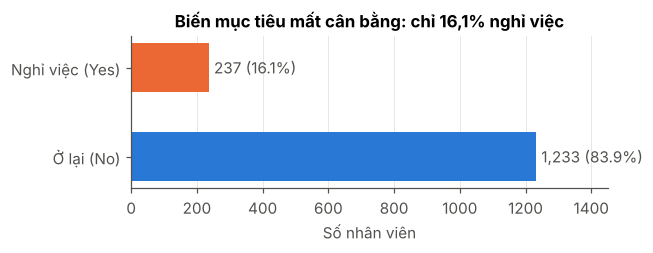

Tỷ lệ mất cân bằng ≈ 5.2 : 1


In [5]:
# 1.4 Phân phối biến mục tiêu: kiểm tra mất cân bằng lớp
counts = raw["Attrition"].value_counts()
share = raw["Attrition"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(["Ở lại (No)", "Nghỉ việc (Yes)"], [counts["No"], counts["Yes"]],
        color=[C_STAY, C_LEAVE], height=0.55)
for i, k in enumerate(["No", "Yes"]):
    ax.text(counts[k] + 15, i, f"{counts[k]:,} ({share[k]:.1%})", va="center", color=C_INK)
ax.set_xlim(0, 1450); ax.set_xlabel("Số nhân viên"); ax.grid(axis="y", visible=False)
ax.set_title("Biến mục tiêu mất cân bằng: chỉ 16,1% nghỉ việc")
save(fig, "fig01_target")
print(f"Tỷ lệ mất cân bằng ≈ {counts['No']/counts['Yes']:.1f} : 1")

**Nhận xét Giai đoạn 1.** 1.470 quan sát × 35 thuộc tính (26 số, 9 chữ), **không có giá trị thiếu**, file đơn nên không phát sinh vấn đề khóa ngoại. Tuy nhiên “sạch về hình thức” chưa có nghĩa là “sạch về nội dung”: (i) 3 cột chỉ có 1 giá trị; (ii) nhiều cột số thực chất là thang thứ bậc; (iii) có những cột chưa rõ ngữ nghĩa (DailyRate, HourlyRate, MonthlyRate); (iv) biến mục tiêu mất cân bằng ≈ 5,2:1 → **Accuracy là thước đo đánh lừa** (đoán “No” cho tất cả đã đạt 83,9%), nên ở phần mô hình sẽ dùng ROC-AUC, PR-AUC và Recall.

# GIAI ĐOẠN 2 — Tiền xử lý và làm sạch dữ liệu
## 2.1 Dữ liệu trùng lặp và cột không mang thông tin

In [6]:
# 2.1 Kiểm tra trùng lặp: trùng toàn bộ dòng, trùng nội dung khi bỏ mã nhân viên, và tính duy nhất của khóa
df = raw.copy()
print("Dòng trùng hoàn toàn:", df.duplicated().sum())
print("Dòng trùng khi bỏ EmployeeNumber:", df.drop(columns="EmployeeNumber").duplicated().sum())
print("EmployeeNumber là khóa duy nhất:", df["EmployeeNumber"].is_unique)

# Cột hằng (1 giá trị duy nhất) không có khả năng phân biệt → loại bỏ
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Cột hằng:", {c: df[c].unique()[0] for c in constant_cols})
df = df.drop(columns=constant_cols + ["EmployeeNumber"])   # EmployeeNumber chỉ là ID
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
print("Kích thước sau khi loại:", df.shape)

Dòng trùng hoàn toàn: 0
Dòng trùng khi bỏ EmployeeNumber: 0
EmployeeNumber là khóa duy nhất: True
Cột hằng: {'EmployeeCount': np.int64(1), 'Over18': 'Y', 'StandardHours': np.int64(80)}
Kích thước sau khi loại: (1470, 32)


## 2.2 Kiểm tra tính nhất quán logic giữa các trường
Dữ liệu không thiếu nhưng có thể **mâu thuẫn nội tại**. Nhóm đặt ra 6 quy tắc nghiệp vụ và kiểm tra từng quy tắc.

In [7]:
# 2.2 Kiểm tra các ràng buộc nghiệp vụ (một bản ghi hợp lệ phải thỏa tất cả)
rules = {
    "YearsAtCompany ≤ TotalWorkingYears": df.YearsAtCompany <= df.TotalWorkingYears,
    "YearsInCurrentRole ≤ YearsAtCompany": df.YearsInCurrentRole <= df.YearsAtCompany,
    "YearsWithCurrManager ≤ YearsAtCompany": df.YearsWithCurrManager <= df.YearsAtCompany,
    "YearsSinceLastPromotion ≤ YearsAtCompany": df.YearsSinceLastPromotion <= df.YearsAtCompany,
    "Age − TotalWorkingYears ≥ 18": (df.Age - df.TotalWorkingYears) >= 18,
    "NumCompaniesWorked=0 ⇒ TotalWorkingYears = YearsAtCompany":
        ~((df.NumCompaniesWorked == 0) & (df.TotalWorkingYears != df.YearsAtCompany)),
}
rule_tbl = pd.DataFrame({"Số bản ghi vi phạm": {k: int((~v).sum()) for k, v in rules.items()}})
rule_tbl

,Số bản ghi vi phạm
YearsAtCompany ≤ TotalWorkingYears,0
YearsInCurrentRole ≤ YearsAtCompany,0
YearsWithCurrManager ≤ YearsAtCompany,0
YearsSinceLastPromotion ≤ YearsAtCompany,0
Age − TotalWorkingYears ≥ 18,0
NumCompaniesWorked=0 ⇒ TotalWorkingYears = YearsAtCompany,197


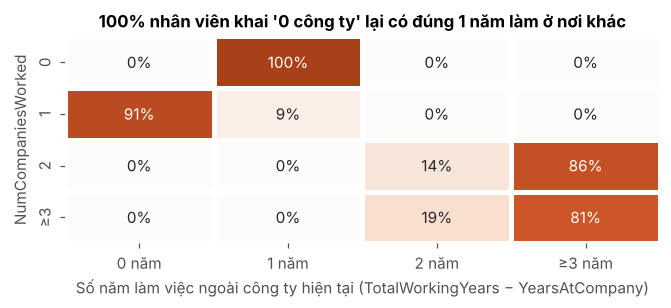

Số bản ghi NumCompaniesWorked=0: 197


In [8]:
# 2.2b Điều tra sâu vi phạm của NumCompaniesWorked: chênh lệch (TotalWorkingYears − YearsAtCompany) theo từng mức
gap = (df.TotalWorkingYears - df.YearsAtCompany)
ct = pd.crosstab(df.NumCompaniesWorked.clip(upper=3), gap.clip(upper=3), normalize="index")
ct.index = ["0", "1", "2", "≥3"]; ct.columns = ["0 năm", "1 năm", "2 năm", "≥3 năm"]
fig, ax = plt.subplots(figsize=(6.2, 2.9))
sns.heatmap(ct, annot=True, fmt=".0%", cmap=CMAP_RATE, cbar=False, linewidths=2, linecolor="white", ax=ax)
ax.set_xlabel("Số năm làm việc ngoài công ty hiện tại (TotalWorkingYears − YearsAtCompany)")
ax.set_ylabel("NumCompaniesWorked")
ax.set_title("100% nhân viên khai '0 công ty' lại có đúng 1 năm làm ở nơi khác")
save(fig, "fig02_numcompanies")
print("Số bản ghi NumCompaniesWorked=0:", (df.NumCompaniesWorked == 0).sum())

**Diễn giải.** Ở mức `NumCompaniesWorked = 1`, 91% bản ghi có tổng năm làm = năm tại công ty → biến này **đếm cả công ty hiện tại**. Theo logic đó, “0 công ty” là bất khả. Cả 197 bản ghi mức 0 đều lệch *đúng 1 năm* — một mẫu hình quá đều để là lỗi nhập liệu ngẫu nhiên, gợi ý **lỗi mã hóa có hệ thống** của bộ sinh dữ liệu. **Quyết định:** *không* tự ý sửa giá trị (không biết giá trị đúng), giữ nguyên nhưng gắn cờ `NCW_inconsistent` và ghi nhận ở phần giới hạn. Biến này cũng không có ý nghĩa thống kê với Attrition (mục 3.9) nên rủi ro thấp.

Tương quan Spearman với MonthlyIncome:


DailyRate      0.016
HourlyRate    -0.020
MonthlyRate    0.054
Name: MonthlyIncome, dtype: float64


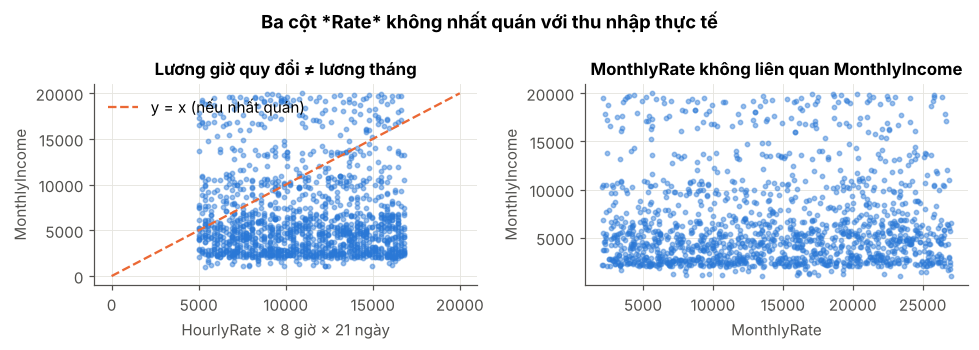

DailyRate: Mann-Whitney p = 0.029
HourlyRate: Mann-Whitney p = 0.798
MonthlyRate: Mann-Whitney p = 0.559


In [9]:
# 2.3 Kiểm tra ba cột "Rate" không có mô tả: nếu là đơn giá lương thì phải tương quan mạnh với MonthlyIncome
df["NCW_inconsistent"] = (df.NumCompaniesWorked == 0).astype(int)
rate_cols = ["DailyRate", "HourlyRate", "MonthlyRate"]
print("Tương quan Spearman với MonthlyIncome:")
print(df[rate_cols + ["MonthlyIncome"]].corr("spearman")["MonthlyIncome"].drop("MonthlyIncome").round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].scatter(df.HourlyRate * 8 * 21, df.MonthlyIncome, s=8, alpha=0.45, color=C_STAY)
lim = [0, 20000]; axes[0].plot(lim, lim, color=C_LEAVE, lw=1.5, ls="--", label="y = x (nếu nhất quán)")
axes[0].set_xlabel("HourlyRate × 8 giờ × 21 ngày"); axes[0].set_ylabel("MonthlyIncome")
axes[0].set_title("Lương giờ quy đổi ≠ lương tháng"); axes[0].legend(frameon=False)
axes[1].scatter(df.MonthlyRate, df.MonthlyIncome, s=8, alpha=0.45, color=C_STAY)
axes[1].set_xlabel("MonthlyRate"); axes[1].set_ylabel("MonthlyIncome")
axes[1].set_title("MonthlyRate không liên quan MonthlyIncome")
fig.suptitle("Ba cột *Rate* không nhất quán với thu nhập thực tế", fontweight="bold")
save(fig, "fig03_rates")

# Kiểm tra thêm: các cột Rate có khác biệt giữa nhóm nghỉ và ở lại không?
for c in rate_cols:
    p = stats.mannwhitneyu(df.loc[df.AttritionFlag == 1, c], df.loc[df.AttritionFlag == 0, c]).pvalue
    print(f"{c}: Mann-Whitney p = {p:.3f}")

**Quyết định:** tương quan ≈ 0 và phân phối gần đều → ba cột *Rate* nhiều khả năng là **số ngẫu nhiên** của bộ sinh dữ liệu, không phải thông tin lương. `DailyRate` có p = 0,029 nhưng đây là kết quả đáng ngờ: biến không có ngữ nghĩa rõ, hai cột “anh em” không có ý nghĩa, và với 3 kiểm định thì ngưỡng Bonferroni là 0,017 → không vượt qua. Đưa vào mô hình chỉ thêm nhiễu → **loại khỏi mô hình** (vẫn giữ trong phần mô tả). Đây là ví dụ cho nguyên tắc *“kiểm tra ngữ nghĩa trước khi tin vào cột số”*.

## 2.4 Ngoại lệ (outliers) — phương pháp IQR

In [10]:
# 2.4 Phát hiện outlier bằng quy tắc IQR (Q1 − 1,5·IQR; Q3 + 1,5·IQR) cho các biến liên tục / đếm
cont = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager", "NumCompaniesWorked", "Age", "DistanceFromHome"]
rows = []
for c in cont:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo, 1), round(hi, 1), n_out, round(n_out / len(df) * 100, 1),
                 round(df[c].skew(), 2), round(df[c].mean(), 1), df[c].median()])
outlier_tbl = pd.DataFrame(rows, columns=["Biến", "Cận dưới", "Cận trên", "Số outlier", "%", "Skewness", "Mean", "Median"])
outlier_tbl.sort_values("Số outlier", ascending=False)

,Biến,Cận dưới,Cận trên,Số outlier,%,Skewness,Mean,Median
0,MonthlyIncome,-5291.0,16581.0,114,7.8,1.37,6502.9,4919.0
4,YearsSinceLastPromotion,-4.5,7.5,107,7.3,1.98,2.2,1.0
2,YearsAtCompany,-6.0,18.0,104,7.1,1.76,7.0,5.0
1,TotalWorkingYears,-7.5,28.5,63,4.3,1.12,11.3,10.0
6,NumCompaniesWorked,-3.5,8.5,52,3.5,1.03,2.7,2.0
3,YearsInCurrentRole,-5.5,14.5,21,1.4,0.92,4.2,3.0
5,YearsWithCurrManager,-5.5,14.5,14,1.0,0.83,4.1,3.0
7,Age,10.5,62.5,0,0.0,0.41,36.9,36.0
8,DistanceFromHome,-16.0,32.0,0,0.0,0.96,9.2,7.0


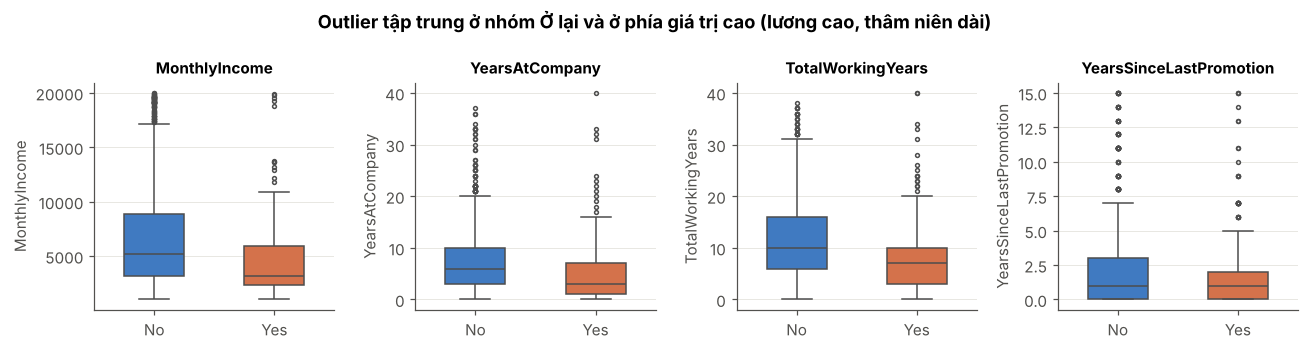

Phân bố JobLevel của 114 outlier thu nhập: {4: 45, 5: 69}


In [11]:
# 2.4b Trực quan hóa outlier: boxplot theo nhóm Attrition — outlier có phải "lỗi" hay là một phân khúc thật?
show = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears", "YearsSinceLastPromotion"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, c in zip(axes, show):
    sns.boxplot(data=df, x="Attrition", y=c, order=["No", "Yes"], palette=[C_STAY, C_LEAVE],
                width=0.5, fliersize=2.5, linewidth=1, ax=ax)
    ax.set_xlabel(""); ax.set_title(c, fontsize=10)
fig.suptitle("Outlier tập trung ở nhóm Ở lại và ở phía giá trị cao (lương cao, thâm niên dài)", fontweight="bold")
save(fig, "fig04_outliers")

# Outlier thu nhập có tương ứng với cấp bậc cao không? (nếu có → giá trị hợp lệ, không phải lỗi)
q3, q1 = df.MonthlyIncome.quantile([.75, .25]); hi = q3 + 1.5 * (q3 - q1)
print("Phân bố JobLevel của 114 outlier thu nhập:", df.loc[df.MonthlyIncome > hi, "JobLevel"].value_counts().sort_index().to_dict())

**Quyết định và lý do.** Outlier thu nhập đều thuộc JobLevel 4–5 (quản lý cấp cao) → đây là **giá trị thật, không phải lỗi**. Xóa đi sẽ (i) mất ~7,8% mẫu, (ii) xóa nhầm nguyên một phân khúc nhân sự cấp cao — vốn là nhóm có tỷ lệ nghỉ thấp nhất, làm lệch kết luận. Vì vậy nhóm **không xóa, không cắt (cap)**, mà xử lý *độ lệch* bằng **biến đổi log1p** cho các biến có skewness > 0,75 khi đưa vào mô hình tuyến tính; Random Forest dựa trên phân ngưỡng nên không nhạy với outlier.

## 2.5 Chiến lược giá trị thiếu: vì sao Median thay vì Mean?

In [12]:
# 2.5 Dữ liệu hiện không thiếu, nhưng pipeline vẫn cài SimpleImputer(median) để chạy an toàn với dữ liệu mới.
# Minh chứng lý do chọn median: với phân phối lệch phải, mean bị kéo lên bởi nhóm lương cao.
s = df.MonthlyIncome
print(f"MonthlyIncome: mean = {s.mean():,.0f} | median = {s.median():,.0f} | skew = {s.skew():.2f}")
print(f"Tỷ lệ nhân viên có lương < mean: {(s < s.mean()).mean():.1%}  → mean không đại diện cho 'nhân viên điển hình'")

# Thí nghiệm nhỏ: xóa ngẫu nhiên 10% giá trị, điền bằng mean vs median, so sai số tuyệt đối trung vị
rng = np.random.default_rng(SEED)
idx = rng.choice(len(s), size=int(0.1 * len(s)), replace=False)
true = s.iloc[idx]
for name, val in [("mean", s.drop(s.index[idx]).mean()), ("median", s.drop(s.index[idx]).median())]:
    print(f"Điền bằng {name:6s}: median |sai số| = {np.median(np.abs(true - val)):,.0f}")

MonthlyIncome: mean = 6,503 | median = 4,919 | skew = 1.37
Tỷ lệ nhân viên có lương < mean: 66.5%  → mean không đại diện cho 'nhân viên điển hình'
Điền bằng mean  : median |sai số| = 3,319
Điền bằng median: median |sai số| = 2,123


## 2.6 Kỹ thuật đặc trưng (feature engineering)

In [13]:
# 2.6 Tạo biến mới có ý nghĩa nghiệp vụ
# (a) Lương tương đối trong cùng cấp bậc: so với trung vị của JobLevel → đo "công bằng nội bộ"
df["RelPayInLevel"] = df.MonthlyIncome / df.groupby("JobLevel").MonthlyIncome.transform("median")
# (b) Số năm bình quân mỗi công ty: đo mức độ "nhảy việc" trong quá khứ
df["YearsPerCompany"] = df.TotalWorkingYears / (df.NumCompaniesWorked + 1)
# (c) Tỷ lệ thời gian chưa được thăng chức trên thâm niên tại công ty
df["PromotionStagnation"] = df.YearsSinceLastPromotion / (df.YearsAtCompany + 1)
# (d) Chỉ số hài lòng tổng hợp (trung bình 4 thang khảo sát 1-4)
sat_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"]
df["SatisfactionIndex"] = df[sat_cols].mean(axis=1)
# (e) Nhóm tuổi và nhóm thâm niên — chỉ dùng cho EDA
df["AgeGroup"] = pd.cut(df.Age, [17, 25, 30, 35, 45, 60], labels=["18-25", "26-30", "31-35", "36-45", "46-60"])
df["TenureGroup"] = pd.cut(df.YearsAtCompany, [-1, 1, 2, 5, 10, 40], labels=["0-1", "2", "3-5", "6-10", ">10"])
df[["RelPayInLevel", "YearsPerCompany", "PromotionStagnation", "SatisfactionIndex"]].describe().round(2)

,RelPayInLevel,YearsPerCompany,PromotionStagnation,SatisfactionIndex
count,1470.00,1470.00,1470.00,1470.00
mean,1.02,4.19,0.24,2.73
std,0.25,4.04,0.27,0.51
min,0.38,0.00,0.00,1.00
25%,0.86,1.60,0.00,2.50
50%,1.00,3.00,0.14,2.75
75%,1.12,5.00,0.43,3.00
max,1.87,38.00,0.92,4.00


## 2.7 Mã hóa (encoding) và chuẩn hóa (scaling) — lựa chọn có lý do

| Nhóm biến | Kỹ thuật | Lý do |
|---|---|---|
| Nhị phân (`OverTime`, `Gender`) | Map 0/1 | Không tạo thêm chiều |
| `BusinessTravel` | **Ordinal** 0/1/2 (Non < Rarely < Frequently) | Có thứ tự tự nhiên theo tần suất đi công tác |
| Danh nghĩa (`Department`, `JobRole`, `EducationField`, `MaritalStatus`) | **One-Hot** (`drop='first'` cho Logistic) | Không có thứ tự; Label Encoding sẽ áp đặt thứ tự giả (VD: Sales > HR) |
| `JobLevel`, `Education`, `StockOptionLevel` | **Giữ dạng số** | Bảo toàn thứ tự, ít tham số |
| 5 thang khảo sát 1–4 | **Giữ dạng số + thêm cờ `_is1` (mức = 1)** | Mục 3.5 cho thấy rủi ro tập trung ở mức thấp nhất (hiệu ứng ngưỡng) và `WorkLifeBalance` không đơn điệu; chỉ dùng số sẽ ép quan hệ thành tuyến tính |
| Biến lệch (skew > 0,75) | **log1p** rồi **StandardScaler** | Giảm ảnh hưởng đuôi phải; Logistic có phạt L2 cần các biến cùng thang để hệ số so sánh được |
| Random Forest | Không scale | Mô hình cây bất biến với phép biến đổi đơn điệu |

Không dùng MinMaxScaler vì nhạy với outlier đã giữ lại ở mục 2.4.

In [14]:
# 2.7 Mã hóa biến nhị phân và thứ bậc
df["OverTime_bin"] = (df.OverTime == "Yes").astype(int)
df["Gender_bin"] = (df.Gender == "Male").astype(int)
df["BusinessTravel_ord"] = df.BusinessTravel.map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
# Cờ ngưỡng cho 5 thang khảo sát: 1 nếu nhân viên chấm mức thấp nhất (bắt hiệu ứng ngưỡng, xem mục 3.5)
survey_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", "WorkLifeBalance", "RelationshipSatisfaction"]
for c in survey_cols:
    df[f"{c}_is1"] = (df[c] == 1).astype(int)

nominal = ["Department", "JobRole", "EducationField", "MaritalStatus"]
numeric = ["Age", "DistanceFromHome", "Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
           "JobSatisfaction", "MonthlyIncome", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
           "RelationshipSatisfaction", "StockOptionLevel", "TotalWorkingYears", "TrainingTimesLastYear",
           "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
           "YearsWithCurrManager", "OverTime_bin", "Gender_bin", "BusinessTravel_ord",
           "RelPayInLevel", "YearsPerCompany", "PromotionStagnation", "NCW_inconsistent"] + [f"{c}_is1" for c in survey_cols]
skewed = [c for c in numeric if df[c].nunique() > 5 and df[c].skew() > 0.75]
print("Biến sẽ log1p:", skewed)
skew_cmp = pd.DataFrame({"skew trước": df[skewed].skew(), "skew sau log1p": np.log1p(df[skewed]).skew()}).round(2)
skew_cmp

Biến sẽ log1p: ['DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'RelPayInLevel', 'YearsPerCompany', 'PromotionStagnation']


,skew trước,skew sau log1p
DistanceFromHome,0.96,-0.03
MonthlyIncome,1.37,0.29
NumCompaniesWorked,1.03,0.09
PercentSalaryHike,0.82,0.51
TotalWorkingYears,1.12,-0.62
YearsAtCompany,1.76,-0.21
YearsInCurrentRole,0.92,-0.38
YearsSinceLastPromotion,1.98,0.72
YearsWithCurrManager,0.83,-0.36
RelPayInLevel,0.83,0.29


# GIAI ĐOẠN 3 — Phân tích, kiểm định giả thuyết và trực quan hóa
## 3.0 Khung giả thuyết
| # | Giả thuyết (H₁) | Cơ sở nghiệp vụ | Kiểm định |
|---|---|---|---|
| H1 | Làm thêm giờ làm tăng nghỉ việc | Kiệt sức (burnout) | χ², Cramér's V |
| H2 | Người nghỉ có thu nhập thấp hơn — kể cả *trong cùng cấp bậc* | Lý thuyết công bằng (Equity theory) | Mann-Whitney U |
| H3 | Rủi ro cao nhất ở giai đoạn đầu sự nghiệp/đầu nhiệm kỳ | Chi phí chuyển việc thấp khi trẻ | χ² |
| H4 | Mức hài lòng càng thấp, nghỉ việc càng cao | Mô hình Herzberg | χ² |
| H5 | Gắn kết tài chính dài hạn (cổ phiếu) giữ chân nhân viên | “Golden handcuffs” | χ² theo phân tầng |
| H6 | Vai trò và tần suất công tác ảnh hưởng nghỉ việc | Đặc thù công việc | χ² |
| H7 | Hiệu suất cao/tăng lương cao giúp giữ người | Pay-for-performance | χ², Mann-Whitney |

Mức ý nghĩa α = 0,05. Vì nhóm thực hiện nhiều kiểm định cùng lúc, p-value được **hiệu chỉnh Bonferroni** ở mục 3.9 (so p với α/m, m = số kiểm định).

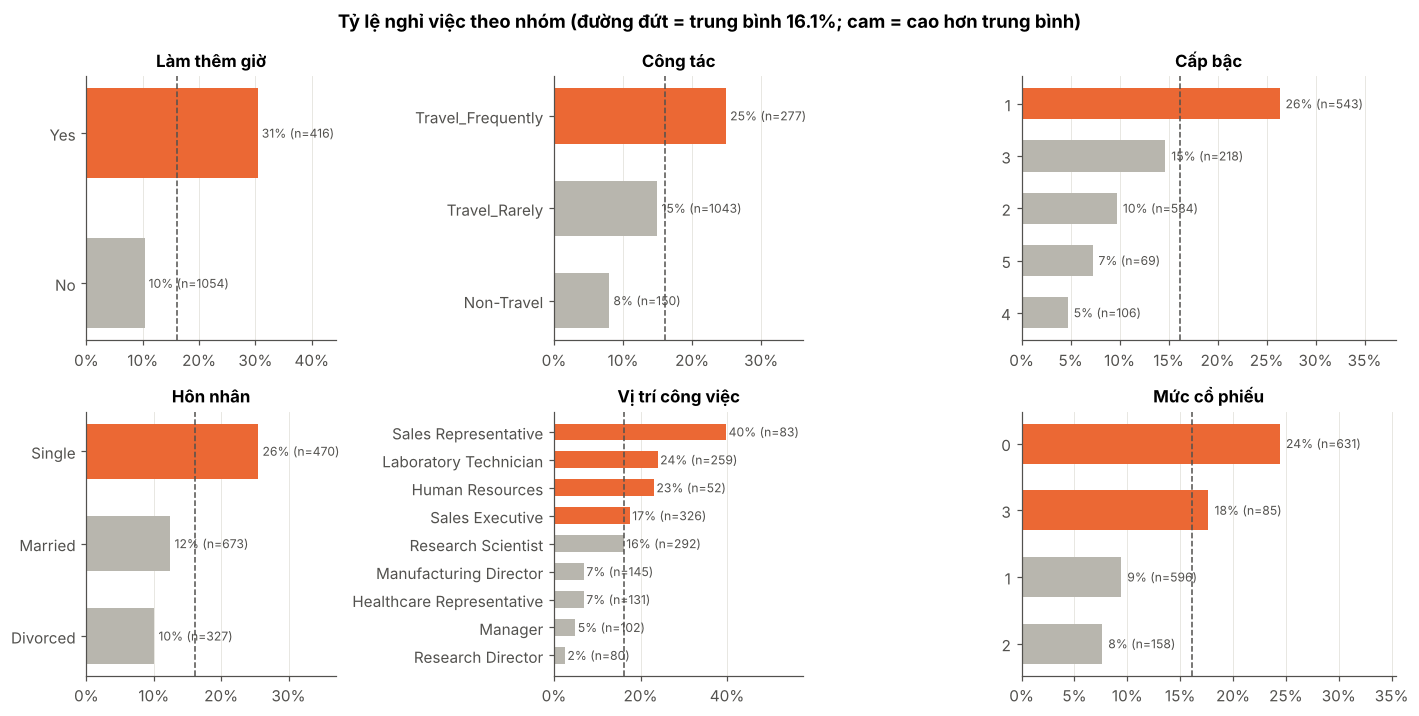

In [15]:
# 3.1 Tổng quan: tỷ lệ nghỉ việc theo các biến phân loại chính (sắp xếp giảm dần, kèm cỡ mẫu)
base = df.AttritionFlag.mean()
panels = [("OverTime", "Làm thêm giờ"), ("MaritalStatus", "Hôn nhân"), ("BusinessTravel", "Công tác"),
          ("JobRole", "Vị trí công việc"), ("JobLevel", "Cấp bậc"), ("StockOptionLevel", "Mức cổ phiếu")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, (col, title) in zip(axes.T.flatten(), panels):
    r = attr_rate(df, col).sort_values("rate")
    colors = [C_LEAVE if v > base else C_GREY for v in r.rate]
    ax.barh(r.index.astype(str), r.rate, color=colors, height=0.6)
    for i, (v, n) in enumerate(zip(r.rate, r.n)):
        ax.text(v + 0.006, i, f"{v:.0%} (n={n})", va="center", fontsize=8, color=C_INK)
    ax.axvline(base, color=C_INK, lw=1, ls="--")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_xlim(0, max(r.rate) * 1.45)
    ax.set_title(title); ax.grid(axis="y", visible=False)
fig.suptitle(f"Tỷ lệ nghỉ việc theo nhóm (đường đứt = trung bình {base:.1%}; cam = cao hơn trung bình)", fontweight="bold")
save(fig, "fig05_overview")

## 3.2 H1 — Làm thêm giờ (OverTime)

Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127 
χ² = 87.6, p = 8.2e-21, Cramér's V = 0.246
Rủi ro tương đối (RR) = 2.93


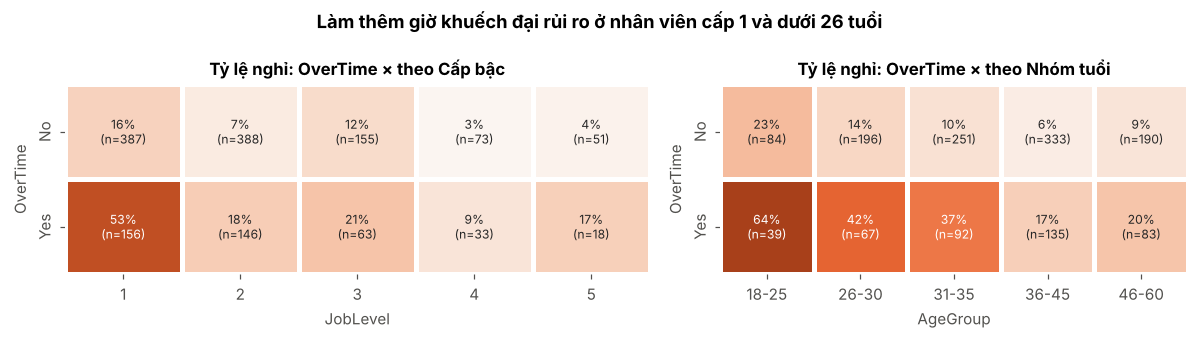

In [16]:
# 3.2 H1: kiểm định χ² độc lập giữa OverTime và Attrition + phân tích tương tác với JobLevel
tab = pd.crosstab(df.OverTime, df.Attrition)
chi2, p, dof, _ = stats.chi2_contingency(tab)
r = attr_rate(df, "OverTime")
print(tab, f"\nχ² = {chi2:.1f}, p = {p:.1e}, Cramér's V = {cramers_v(tab):.3f}")
print(f"Rủi ro tương đối (RR) = {r.rate['Yes'] / r.rate['No']:.2f}")

# Tương tác: OverTime × JobLevel và OverTime × nhóm tuổi
fig, axes = plt.subplots(1, 2, figsize=(11, 3.1), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, col, ttl in [(axes[0], "JobLevel", "theo Cấp bậc"), (axes[1], "AgeGroup", "theo Nhóm tuổi")]:
    rate = df.pivot_table(index="OverTime", columns=col, values="AttritionFlag", aggfunc="mean", observed=True)
    n = df.pivot_table(index="OverTime", columns=col, values="AttritionFlag", aggfunc="size", observed=True)
    annot = rate.map(lambda v: f"{v:.0%}") + "\n(n=" + n.astype(str) + ")"
    sns.heatmap(rate, annot=annot, fmt="", cmap=CMAP_RATE, vmin=0, vmax=0.6, cbar=False,
                linewidths=2, linecolor="white", annot_kws={"fontsize": 8}, ax=ax)
    ax.set_title(f"Tỷ lệ nghỉ: OverTime × {ttl}"); ax.set_ylabel("OverTime")
fig.suptitle("Làm thêm giờ khuếch đại rủi ro ở nhân viên cấp 1 và dưới 26 tuổi", fontweight="bold")
save(fig, "fig06_overtime")

## 3.3 H2 — Thu nhập và công bằng nội bộ

MonthlyIncome: median nghỉ = 3,202.00 | median ở lại = 5,204.00 | p = 3.0e-14
RelPayInLevel: median nghỉ = 0.96 | median ở lại = 1.01 | p = 8.1e-03

Trong từng cấp bậc:
 JobLevel   n  n nghỉ  Median nghỉ  Median ở lại      p  p_Bonferroni                                        Kết luận
        1 543     143       2437.0        2719.0 0.0004        0.0021                                    Có khác biệt
        2 534      52       5346.0        5334.5 0.3072        1.0000                                 Không khác biệt
        3 218      32       9887.0        9982.5 0.1605        0.8026                                 Không khác biệt
        4 106       5      13194.0       16307.0 0.0040        0.0201 Có ý nghĩa nhưng n nghỉ < 20 → không đủ tin cậy
        5  69       5      19545.0       19199.5 0.2057        1.0000                                 Không khác biệt


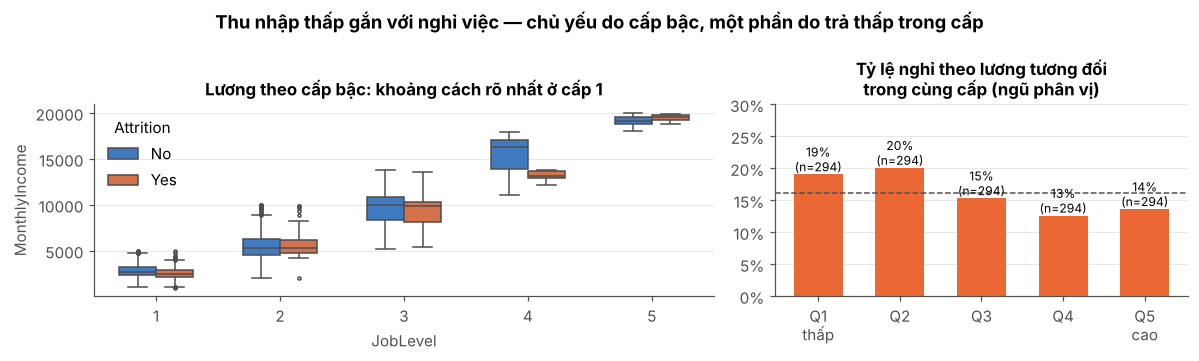

           rate    n
RelPayQ             
Q1\nthấp  0.190  294
Q2        0.201  294
Q3        0.153  294
Q4        0.126  294
Q5\ncao   0.136  294


In [17]:
# 3.3 H2: so sánh thu nhập giữa hai nhóm bằng Mann-Whitney U (phi tham số vì lương lệch phải)
def mwu(col, frame=df):
    # Trả về trung vị của nhóm nghỉ, nhóm ở lại và p-value của kiểm định Mann-Whitney U
    a, b = frame.loc[frame.AttritionFlag == 1, col], frame.loc[frame.AttritionFlag == 0, col]
    return a.median(), b.median(), stats.mannwhitneyu(a, b).pvalue

for col in ["MonthlyIncome", "RelPayInLevel"]:
    m1, m0, p = mwu(col)
    print(f"{col}: median nghỉ = {m1:,.2f} | median ở lại = {m0:,.2f} | p = {p:.1e}")
# Trong từng cấp bậc: 5 kiểm định cùng lúc → báo cáo số người nghỉ và hiệu chỉnh Bonferroni (×5)
lv = []
for jl in range(1, 6):
    sub_l = df[df.JobLevel == jl]
    m1, m0, p = mwu("MonthlyIncome", sub_l)
    lv.append([jl, len(sub_l), int(sub_l.AttritionFlag.sum()), m1, m0, p])
lv = pd.DataFrame(lv, columns=["JobLevel", "n", "n nghỉ", "Median nghỉ", "Median ở lại", "p"])
lv["p_Bonferroni"] = bonferroni(lv.p)
lv["Kết luận"] = np.where((lv.p_Bonferroni < 0.05) & (lv["n nghỉ"] >= 20), "Có khác biệt",
                 np.where(lv.p_Bonferroni < 0.05, "Có ý nghĩa nhưng n nghỉ < 20 → không đủ tin cậy", "Không khác biệt"))
print("\nTrong từng cấp bậc:")
print(lv.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.5, 1]})
sns.boxplot(data=df, x="JobLevel", y="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"],
            palette=[C_STAY, C_LEAVE], fliersize=2, linewidth=1, width=0.6, ax=axes[0])
axes[0].set_title("Lương theo cấp bậc: khoảng cách rõ nhất ở cấp 1"); axes[0].legend(title="Attrition", frameon=False)
# Tỷ lệ nghỉ theo ngũ phân vị lương tương đối trong cấp
df["RelPayQ"] = pd.qcut(df.RelPayInLevel, 5, labels=["Q1\nthấp", "Q2", "Q3", "Q4", "Q5\ncao"])
r = attr_rate(df, "RelPayQ")
axes[1].bar(range(5), r.rate, color=C_LEAVE, width=0.6)
for i, (v, n) in enumerate(zip(r.rate, r.n)):
    axes[1].text(i, v + 0.005, f"{v:.0%}\n(n={n})", ha="center", fontsize=8)
axes[1].axhline(base, color=C_INK, ls="--", lw=1)
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(r.index); axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); axes[1].set_ylim(0, 0.3)
axes[1].set_title("Tỷ lệ nghỉ theo lương tương đối\ntrong cùng cấp (ngũ phân vị)"); axes[1].set_xlabel("")
fig.suptitle("Thu nhập thấp gắn với nghỉ việc — chủ yếu do cấp bậc, một phần do trả thấp trong cấp", fontweight="bold")
save(fig, "fig07_income")
print(r.round(3))

## 3.4 H3 — Giai đoạn sự nghiệp: tuổi và thâm niên

AgeGroup χ² p = 2.7e-12, V = 0.202
TenureGroup χ² p = 8.9e-16, V = 0.228


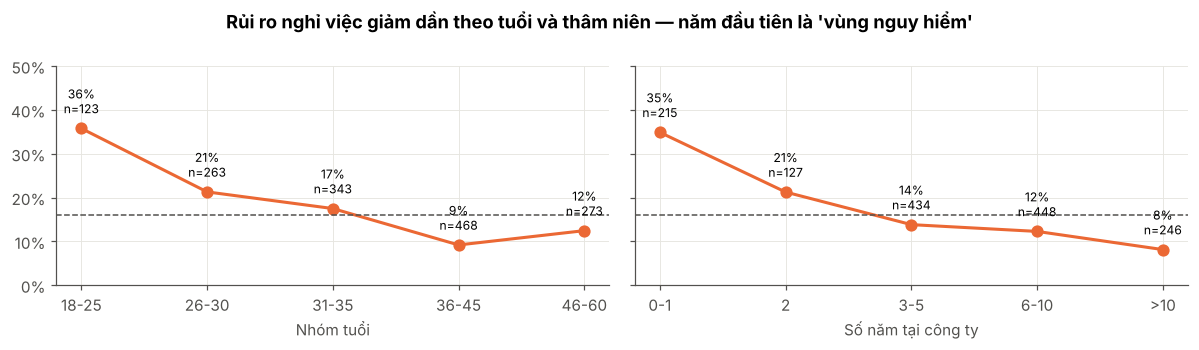

In [18]:
# 3.4 H3: tỷ lệ nghỉ theo nhóm tuổi và nhóm thâm niên, kèm cỡ mẫu từng nhóm
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, col, xl in [(axes[0], "AgeGroup", "Nhóm tuổi"), (axes[1], "TenureGroup", "Số năm tại công ty")]:
    r = attr_rate(df, col)
    ax.plot(range(len(r)), r.rate, color=C_LEAVE, marker="o", ms=7, lw=2)
    for i, (v, n) in enumerate(zip(r.rate, r.n)):
        ax.annotate(f"{v:.0%}\nn={n}", (i, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
    ax.axhline(base, color=C_INK, ls="--", lw=1)
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.index); ax.set_xlabel(xl)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, 0.5)
    tab = pd.crosstab(df[col], df.Attrition); print(col, f"χ² p = {stats.chi2_contingency(tab)[1]:.1e}, V = {cramers_v(tab):.3f}")
fig.suptitle("Rủi ro nghỉ việc giảm dần theo tuổi và thâm niên — năm đầu tiên là 'vùng nguy hiểm'", fontweight="bold")
save(fig, "fig08_career")

## 3.5 H4 — Mức độ hài lòng và gắn kết

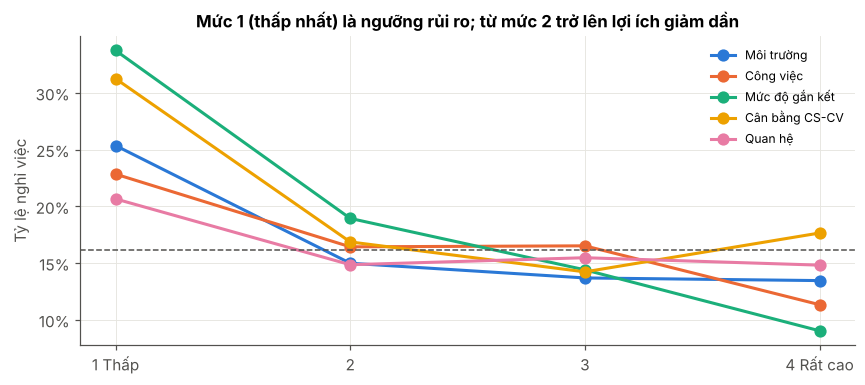

      Thang đo  Tỷ lệ nghỉ @1  Tỷ lệ nghỉ @4   χ² p  Cramér V  p (mức 1 vs 2–4)
    Môi trường         0.2535         0.1345 0.0001    0.1237            0.0000
     Công việc         0.2284         0.1133 0.0006    0.1091            0.0007
Mức độ gắn kết         0.3373         0.0903 0.0000    0.1392            0.0000
Cân bằng CS-CV         0.3125         0.1765 0.0010    0.1054            0.0003
       Quan hệ         0.2065         0.1481 0.1550    0.0597            0.0293


,Thang đo,Tỷ lệ nghỉ @1,Tỷ lệ nghỉ @4,χ² p,Cramér V,p (mức 1 vs 2–4)
0,Môi trường,0.2535,0.1345,0.0001,0.1237,0.0000
1,Công việc,0.2284,0.1133,0.0006,0.1091,0.0007
2,Mức độ gắn kết,0.3373,0.0903,0.0000,0.1392,0.0000
3,Cân bằng CS-CV,0.3125,0.1765,0.0010,0.1054,0.0003
4,Quan hệ,0.2065,0.1481,0.1550,0.0597,0.0293


In [19]:
# 3.5 H4: tỷ lệ nghỉ theo từng mức của 5 thang khảo sát (1 = thấp nhất, 4 = cao nhất)
surveys = ["EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", "WorkLifeBalance", "RelationshipSatisfaction"]
labels = ["Môi trường", "Công việc", "Mức độ gắn kết", "Cân bằng CS-CV", "Quan hệ"]
cats = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # bảng màu phân loại cố định, đã kiểm định CVD
fig, ax = plt.subplots(figsize=(8, 3.6))
res = []
for c, lab, col in zip(surveys, labels, cats):
    r = attr_rate(df, c)
    ax.plot(r.index, r.rate, marker="o", ms=7, lw=2, color=col)
    tab = pd.crosstab(df[c], df.Attrition)                           # χ² trên cả 4 mức
    tab1 = pd.crosstab(df[c] == 1, df.Attrition)                     # χ² 2×2: mức 1 so với các mức 2–4
    res.append([lab, r.rate.iloc[0], r.rate.iloc[-1], stats.chi2_contingency(tab)[1], cramers_v(tab),
                stats.chi2_contingency(tab1)[1]])
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["1 Thấp", "2", "3", "4 Rất cao"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylabel("Tỷ lệ nghỉ việc")
ax.axhline(base, color=C_INK, ls="--", lw=1)
ax.legend(labels, frameon=False, fontsize=8, loc="upper right")
ax.set_title("Mức 1 (thấp nhất) là ngưỡng rủi ro; từ mức 2 trở lên lợi ích giảm dần")
save(fig, "fig09_satisfaction")
sat_tbl = pd.DataFrame(res, columns=["Thang đo", "Tỷ lệ nghỉ @1", "Tỷ lệ nghỉ @4", "χ² p", "Cramér V",
                                    "p (mức 1 vs 2–4)"])
print(sat_tbl.round(4).to_string(index=False))
sat_tbl.round(4)

## 3.6 H5 — Cổ phiếu và tình trạng hôn nhân: một biến gây nhiễu cấu trúc

Cỡ mẫu:
 StockOptionLevel    0    1   2   3
MaritalStatus                     
Divorced            8  195  75  49
Married           153  401  83  36
Single            470    0   0   0


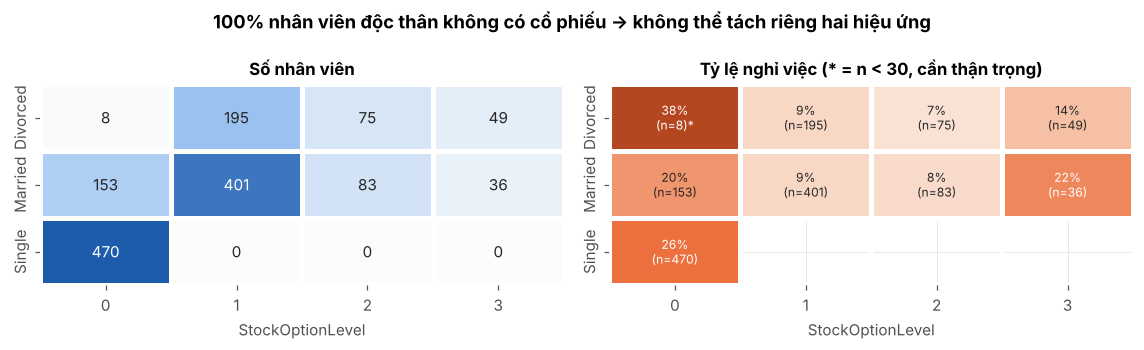

Attrition          No  Yes
StockOptionLevel          
False             127   34
True              756   83 
Nhóm đã/đã từng kết hôn: χ² p = 8.7e-05
           rate    n
HasStock            
False     0.211  161
True      0.099  839


In [20]:
# 3.6 H5: bảng chéo MaritalStatus × StockOptionLevel (cỡ mẫu và tỷ lệ nghỉ)
cnt = pd.crosstab(df.MaritalStatus, df.StockOptionLevel)
rate = df.pivot_table(index="MaritalStatus", columns="StockOptionLevel", values="AttritionFlag", aggfunc="mean")
print("Cỡ mẫu:\n", cnt)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
sns.heatmap(cnt, annot=True, fmt="d", cmap=LinearSegmentedColormap.from_list("b", ["#fcfcfb", "#86b6ef", "#1c5cab"]),
            cbar=False, linewidths=2, linecolor="white", ax=axes[0])
axes[0].set_title("Số nhân viên"); axes[0].set_ylabel("")
# Ghi tỷ lệ kèm cỡ mẫu; ô có n < 30 đánh dấu * vì tỷ lệ rất bất ổn
annot = rate.copy().astype(object)
for i in rate.index:
    for j in rate.columns:
        v, n = rate.loc[i, j], cnt.loc[i, j]
        annot.loc[i, j] = "" if pd.isna(v) else f"{v:.0%}\n(n={n}){'*' if n < 30 else ''}"
sns.heatmap(rate, annot=annot, fmt="", cmap=CMAP_RATE, vmin=0, vmax=0.4, annot_kws={"fontsize": 8},
            cbar=False, linewidths=2, linecolor="white", ax=axes[1])
axes[1].set_title("Tỷ lệ nghỉ việc (* = n < 30, cần thận trọng)"); axes[1].set_ylabel("")
fig.suptitle("100% nhân viên độc thân không có cổ phiếu → không thể tách riêng hai hiệu ứng", fontweight="bold")
save(fig, "fig10_stock_marital")

# Phân tầng: trong nhóm KHÔNG độc thân, cổ phiếu còn tác động không?
sub = df[df.MaritalStatus != "Single"]
t = pd.crosstab(sub.StockOptionLevel > 0, sub.Attrition)
print(t, f"\nNhóm đã/đã từng kết hôn: χ² p = {stats.chi2_contingency(t)[1]:.1e}")
print(attr_rate(sub.assign(HasStock=sub.StockOptionLevel > 0), "HasStock").round(3))

## 3.7 H6 & H7 — Vai trò, công tác và hiệu suất

Phân phối PerformanceRating: {3: 1244, 4: 226}
                   min  max  median
PerformanceRating                  
3                   11   19    14.0
4                   20   25    22.0
Spearman(PerformanceRating, PercentSalaryHike) = 0.629


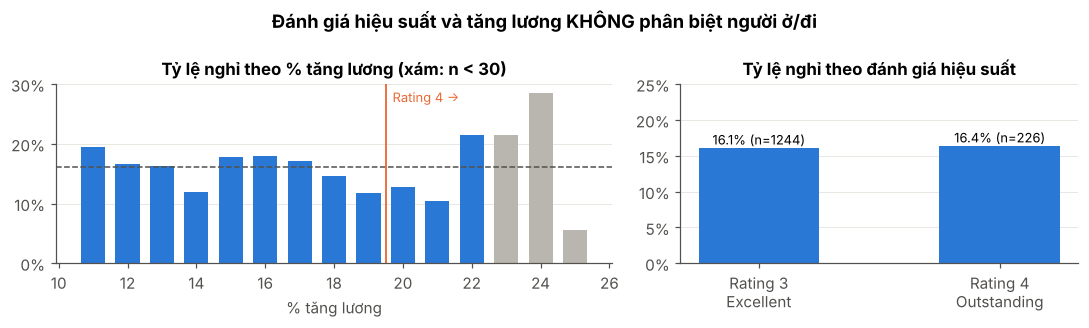

PerformanceRating χ² p = 0.99


In [21]:
# 3.7 H7: PerformanceRating chỉ có 2 mức và quyết định gần như hoàn toàn PercentSalaryHike
print("Phân phối PerformanceRating:", df.PerformanceRating.value_counts().to_dict())
print(df.groupby("PerformanceRating").PercentSalaryHike.agg(["min", "max", "median"]))
print("Spearman(PerformanceRating, PercentSalaryHike) =", round(stats.spearmanr(df.PerformanceRating, df.PercentSalaryHike)[0], 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [1.4, 1]})
r = attr_rate(df, "PercentSalaryHike")
axes[0].bar(r.index, r.rate, color=[C_GREY if n < 30 else C_STAY for n in r.n], width=0.7)
axes[0].axhline(base, color=C_INK, ls="--", lw=1); axes[0].axvline(19.5, color=C_LEAVE, lw=1.2)
axes[0].text(19.7, 0.27, "Rating 4 →", color=C_LEAVE, fontsize=8.5)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); axes[0].set_xlabel("% tăng lương")
axes[0].set_title("Tỷ lệ nghỉ theo % tăng lương (xám: n < 30)"); axes[0].grid(axis="x", visible=False)
r2 = attr_rate(df, "PerformanceRating")
axes[1].bar(["Rating 3\nExcellent", "Rating 4\nOutstanding"], r2.rate, color=C_STAY, width=0.5)
for i, (v, n) in enumerate(zip(r2.rate, r2.n)): axes[1].text(i, v + 0.005, f"{v:.1%} (n={n})", ha="center", fontsize=8.5)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); axes[1].set_ylim(0, 0.25)
axes[1].set_title("Tỷ lệ nghỉ theo đánh giá hiệu suất"); axes[1].grid(axis="x", visible=False)
fig.suptitle("Đánh giá hiệu suất và tăng lương KHÔNG phân biệt người ở/đi", fontweight="bold")
save(fig, "fig11_performance")
for c in ["PerformanceRating"]:
    tab = pd.crosstab(df[c], df.Attrition); print(c, "χ² p =", round(stats.chi2_contingency(tab)[1], 3))

## 3.8 Tương quan và đa cộng tuyến

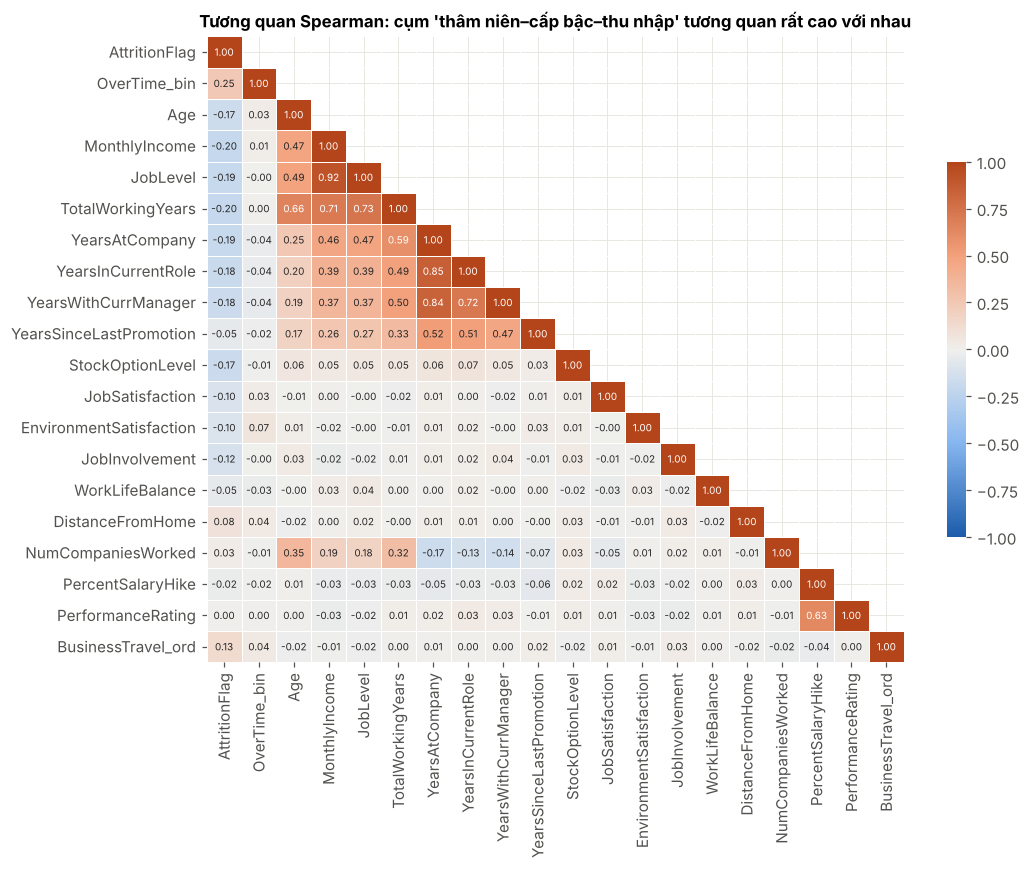

                   a                  b  rho
            JobLevel      MonthlyIncome 0.92
  YearsInCurrentRole     YearsAtCompany 0.85
YearsWithCurrManager     YearsAtCompany 0.84
   TotalWorkingYears           JobLevel 0.73
YearsWithCurrManager YearsInCurrentRole 0.72
   TotalWorkingYears      MonthlyIncome 0.71

Tương quan mạnh nhất với Attrition:
OverTime_bin            0.246
TotalWorkingYears      -0.199
MonthlyIncome          -0.198
YearsAtCompany         -0.190
JobLevel               -0.190
YearsInCurrentRole     -0.181
YearsWithCurrManager   -0.175
StockOptionLevel       -0.172
Name: AttritionFlag, dtype: float64


In [22]:
# 3.8 Ma trận tương quan Spearman (phù hợp biến thứ bậc và lệch) cho các biến số + biến mục tiêu
corr_cols = ["AttritionFlag", "OverTime_bin", "Age", "MonthlyIncome", "JobLevel", "TotalWorkingYears", "YearsAtCompany",
             "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion", "StockOptionLevel",
             "JobSatisfaction", "EnvironmentSatisfaction", "JobInvolvement", "WorkLifeBalance",
             "DistanceFromHome", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating", "BusinessTravel_ord"]
cm = df[corr_cols].corr("spearman")
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 6.5}, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Tương quan Spearman: cụm 'thâm niên–cấp bậc–thu nhập' tương quan rất cao với nhau")
save(fig, "fig12_corr")

# Các cặp biến độc lập có |ρ| > 0,7 → nguy cơ đa cộng tuyến
pairs = cm.where(mask == False).stack().reset_index(); pairs.columns = ["a", "b", "rho"]
pairs = pairs[(pairs.a != pairs.b) & (pairs.a != "AttritionFlag") & (pairs.b != "AttritionFlag")]
print(pairs[pairs.rho.abs() > 0.7].drop_duplicates("rho").sort_values("rho", ascending=False).round(2).to_string(index=False))
print("\nTương quan mạnh nhất với Attrition:")
print(cm["AttritionFlag"].drop("AttritionFlag").sort_values(key=abs, ascending=False).head(8).round(3))

## 3.9 Tổng hợp kiểm định và hiệu chỉnh đa kiểm định (Bonferroni)

In [23]:
# 3.9 Chạy toàn bộ kiểm định, hiệu chỉnh p-value theo Bonferroni (28 kiểm định → so p với 0,05/28)
cat_tests = ["OverTime", "MaritalStatus", "JobRole", "JobLevel", "StockOptionLevel", "BusinessTravel", "Department",
             "EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction", "WorkLifeBalance", "EducationField",
             "RelationshipSatisfaction", "Education", "Gender", "PerformanceRating"]
num_tests = ["TotalWorkingYears", "MonthlyIncome", "YearsAtCompany", "YearsWithCurrManager", "Age", "YearsInCurrentRole",
             "RelPayInLevel", "DistanceFromHome", "TrainingTimesLastYear", "YearsSinceLastPromotion",
             "NumCompaniesWorked", "PercentSalaryHike"]
out = []
for c in cat_tests:
    tab = pd.crosstab(df[c], df.Attrition)
    out.append([c, "χ²", stats.chi2_contingency(tab)[1], f"V = {cramers_v(tab):.2f}"])
for c in num_tests:
    m1, m0, p = mwu(c)
    out.append([c, "Mann-Whitney", p, f"median {m1:,.2f} vs {m0:,.2f}"])
tests = pd.DataFrame(out, columns=["Biến", "Kiểm định", "p", "Độ mạnh / so sánh trung vị (nghỉ vs ở lại)"])
tests["p_Bonferroni"] = bonferroni(tests.p)
tests["Kết luận (α=0,05)"] = np.where(tests.p_Bonferroni < 0.05, "Có liên hệ", "Không đủ bằng chứng")
tests = tests.sort_values("p")
print("Số biến có ý nghĩa sau hiệu chỉnh:", (tests.p_Bonferroni < 0.05).sum(), "/", len(tests))
print(tests.assign(p=tests.p.map("{:.1e}".format), p_Bonferroni=tests.p_Bonferroni.map("{:.1e}".format)).to_string(index=False))
tests.assign(p=tests.p.map("{:.1e}".format), p_Bonferroni=tests.p_Bonferroni.map("{:.1e}".format))

Số biến có ý nghĩa sau hiệu chỉnh: 16 / 28
                    Biến    Kiểm định       p Độ mạnh / so sánh trung vị (nghỉ vs ở lại) p_Bonferroni   Kết luận (α=0,05)
                OverTime           χ² 8.2e-21                                   V = 0.25      2.3e-19          Có liên hệ
                 JobRole           χ² 2.8e-15                                   V = 0.24      7.7e-14          Có liên hệ
                JobLevel           χ² 6.6e-15                                   V = 0.22      1.9e-13          Có liên hệ
       TotalWorkingYears Mann-Whitney 2.4e-14                       median 7.00 vs 10.00      6.7e-13          Có liên hệ
           MonthlyIncome Mann-Whitney 3.0e-14                median 3,202.00 vs 5,204.00      8.3e-13          Có liên hệ
          YearsAtCompany Mann-Whitney 2.9e-13                        median 3.00 vs 6.00      8.2e-12          Có liên hệ
        StockOptionLevel           χ² 4.4e-13                                   V = 0.20      1.2e-11  

,Biến,Kiểm định,p,Độ mạnh / so sánh trung vị (nghỉ vs ở lại),p_Bonferroni,"Kết luận (α=0,05)"
0,OverTime,χ²,8.2e-21,V = 0.25,2.3e-19,Có liên hệ
2,JobRole,χ²,2.8e-15,V = 0.24,7.7e-14,Có liên hệ
3,JobLevel,χ²,6.6e-15,V = 0.22,1.9e-13,Có liên hệ
16,TotalWorkingYears,Mann-Whitney,2.4e-14,median 7.00 vs 10.00,6.7e-13,Có liên hệ
17,MonthlyIncome,Mann-Whitney,3.0e-14,"median 3,202.00 vs 5,204.00",8.3e-13,Có liên hệ
18,YearsAtCompany,Mann-Whitney,2.9e-13,median 3.00 vs 6.00,8.2e-12,Có liên hệ
4,StockOptionLevel,χ²,4.4e-13,V = 0.20,1.2e-11,Có liên hệ
21,YearsInCurrentRole,Mann-Whitney,4.4e-12,median 2.00 vs 3.00,1.2e-10,Có liên hệ
19,YearsWithCurrManager,Mann-Whitney,1.8e-11,median 2.00 vs 3.00,5.1e-10,Có liên hệ
20,Age,Mann-Whitney,5.3e-11,median 32.00 vs 36.00,1.5e-09,Có liên hệ


## 3.10 Mô hình dự báo rủi ro nghỉ việc (Chương 11 – học có giám sát)
Mục tiêu không phải “mô hình chính xác nhất” mà là (1) **xác nhận đa biến** các yếu tố đã tìm thấy khi kiểm soát lẫn nhau, và (2) tạo **điểm rủi ro** để HR ưu tiên can thiệp.

- Chia train/test 80/20 **phân tầng (stratified)** để giữ tỷ lệ 16% ở cả hai tập; mọi tiền xử lý nằm trong `Pipeline` → **không rò rỉ dữ liệu**.
- `class_weight='balanced'` để xử lý mất cân bằng lớp.
- So sánh Logistic Regression (dễ diễn giải, odds ratio) và Random Forest (bắt tương tác phi tuyến).
- **Đạo đức:** kiểm tra thêm phiên bản *không dùng* Gender, Age, MaritalStatus — các thuộc tính được bảo vệ không nên dùng để ra quyết định nhân sự.

In [24]:
# 3.10a Chuẩn bị X, y và chia tập có phân tầng
y = df.AttritionFlag
X = df[numeric + nominal].copy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_tr.shape, f"(nghỉ {y_tr.mean():.1%}) | Test:", X_te.shape, f"(nghỉ {y_te.mean():.1%})")

def make_pre(num_cols, nom_cols, scale=True):
    # Tiền xử lý: median-impute → log1p biến lệch → scale (cho Logistic); one-hot cho biến danh nghĩa
    sk = [c for c in num_cols if c in skewed]; rest = [c for c in num_cols if c not in skewed]
    num_skew = [("imp", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]
    num_rest = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_skew.append(("sc", StandardScaler())); num_rest.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("skew", Pipeline(num_skew), sk),
        ("num", Pipeline(num_rest), rest),
        ("nom", OneHotEncoder(drop="first" if scale else None, handle_unknown="ignore"), nom_cols),
    ], verbose_feature_names_out=False)

# Cả hai mô hình đều được tinh chỉnh tham số bằng GridSearchCV (CV 5-fold trên tập train) để so sánh công bằng
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
search = {
    "Logistic Regression": (Pipeline([("pre", make_pre(numeric, nominal)),
                                      ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
                            {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Random Forest": (Pipeline([("pre", make_pre(numeric, nominal, scale=False)),
                                ("clf", RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                                               random_state=SEED, n_jobs=-1))]),
                      {"clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3]}),
}

Train: (1176, 36) (nghỉ 16.2%) | Test: (294, 36) (nghỉ 16.0%)


In [25]:
# 3.10b Tinh chỉnh tham số bằng GridSearchCV (cv=5) trên tập train, rồi đánh giá MỘT lần trên tập test độc lập
rows, probas, models = [], {}, {}
for name, (pipe, grid) in search.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_tr, y_tr)
    m = gs.best_estimator_; models[name] = m
    pr = m.predict_proba(X_te)[:, 1]; probas[name] = pr
    pred = (pr >= 0.5).astype(int)
    rows.append([name, str(gs.best_params_).replace("clf__", ""),
                 f"{gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.3f}",
                 roc_auc_score(y_te, pr), average_precision_score(y_te, pr),
                 recall_score(y_te, pred), precision_score(y_te, pred), f1_score(y_te, pred)])
# Mốc so sánh: mô hình "đoán No cho tất cả"
rows.append(["Baseline (luôn đoán No)", "—", "0.500", 0.5, y_te.mean(), 0.0, 0.0, 0.0])
perf = pd.DataFrame(rows, columns=["Mô hình", "Tham số tốt nhất", "CV ROC-AUC (mean ± std)", "Test ROC-AUC", "Test PR-AUC",
                                   "Recall@0.5", "Precision@0.5", "F1@0.5"])
print(perf.round(3).to_string(index=False))
perf.round(3)

                Mô hình                             Tham số tốt nhất CV ROC-AUC (mean ± std)  Test ROC-AUC  Test PR-AUC  Recall@0.5  Precision@0.5  F1@0.5
    Logistic Regression                                  {'C': 0.03}           0.849 ± 0.030         0.803        0.584        0.66          0.392   0.492
          Random Forest {'max_features': 0.3, 'min_samples_leaf': 3}           0.819 ± 0.022         0.762        0.405        0.17          0.421   0.242
Baseline (luôn đoán No)                                            —                   0.500         0.500        0.160        0.00          0.000   0.000


,Mô hình,Tham số tốt nhất,CV ROC-AUC (mean ± std),Test ROC-AUC,Test PR-AUC,Recall@0.5,Precision@0.5,F1@0.5
0,Logistic Regression,{'C': 0.03},0.849 ± 0.030,0.803,0.584,0.66,0.392,0.492
1,Random Forest,"{'max_features': 0.3, 'min_samples_leaf': 3}",0.819 ± 0.022,0.762,0.405,0.17,0.421,0.242
2,Baseline (luôn đoán No),—,0.500,0.500,0.160,0.00,0.000,0.000


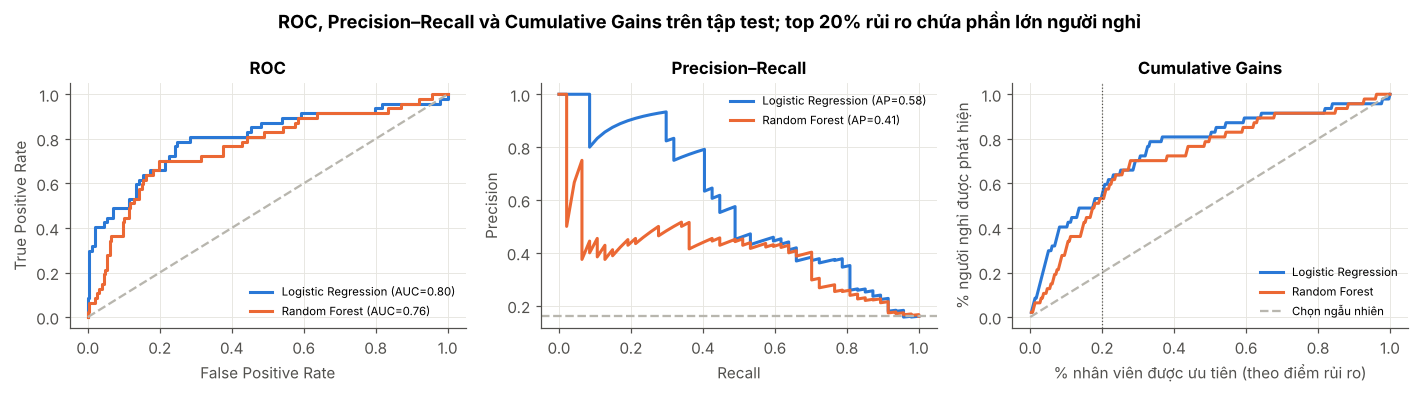

Logistic: nhóm 20% điểm rủi ro cao nhất (58 người) chứa 53% số người nghỉ thực tế → lift = 2.7x so với chọn ngẫu nhiên; tỷ lệ nghỉ trong nhóm = 43%


In [26]:
# 3.10c Đường ROC, Precision-Recall và đường Cumulative Gains (giá trị kinh doanh của việc xếp hạng rủi ro)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for (name, pr), col in zip(probas.items(), [C_STAY, C_LEAVE]):
    fpr, tpr, _ = roc_curve(y_te, pr); axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={roc_auc_score(y_te, pr):.2f})")
    pc, rc, _ = precision_recall_curve(y_te, pr); axes[1].plot(rc, pc, color=col, lw=2, label=f"{name} (AP={average_precision_score(y_te, pr):.2f})")
    order = np.argsort(-pr); gains = np.cumsum(y_te.values[order]) / y_te.sum()
    axes[2].plot(np.arange(1, len(pr) + 1) / len(pr), gains, color=col, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], color=C_GREY, ls="--"); axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate"); axes[0].set_title("ROC")
axes[1].axhline(y_te.mean(), color=C_GREY, ls="--"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–Recall")
axes[2].plot([0, 1], [0, 1], color=C_GREY, ls="--", label="Chọn ngẫu nhiên")
axes[2].axvline(0.2, color=C_INK, lw=0.8, ls=":")
axes[2].set_xlabel("% nhân viên được ưu tiên (theo điểm rủi ro)"); axes[2].set_ylabel("% người nghỉ được phát hiện"); axes[2].set_title("Cumulative Gains")
for ax in axes: ax.legend(frameon=False, fontsize=7.5, loc="lower right" if ax is not axes[1] else "upper right")
fig.suptitle("ROC, Precision–Recall và Cumulative Gains trên tập test; top 20% rủi ro chứa phần lớn người nghỉ", fontweight="bold")
save(fig, "fig13_model_curves")

lr_pr = probas["Logistic Regression"]; order = np.argsort(-lr_pr)
top20 = int(0.2 * len(lr_pr))
cap = y_te.values[order][:top20].sum() / y_te.sum()
print(f"Logistic: nhóm 20% điểm rủi ro cao nhất ({top20} người) chứa {cap:.0%} số người nghỉ thực tế "
      f"→ lift = {cap / 0.2:.1f}x so với chọn ngẫu nhiên; tỷ lệ nghỉ trong nhóm = {y_te.values[order][:top20].mean():.0%}")

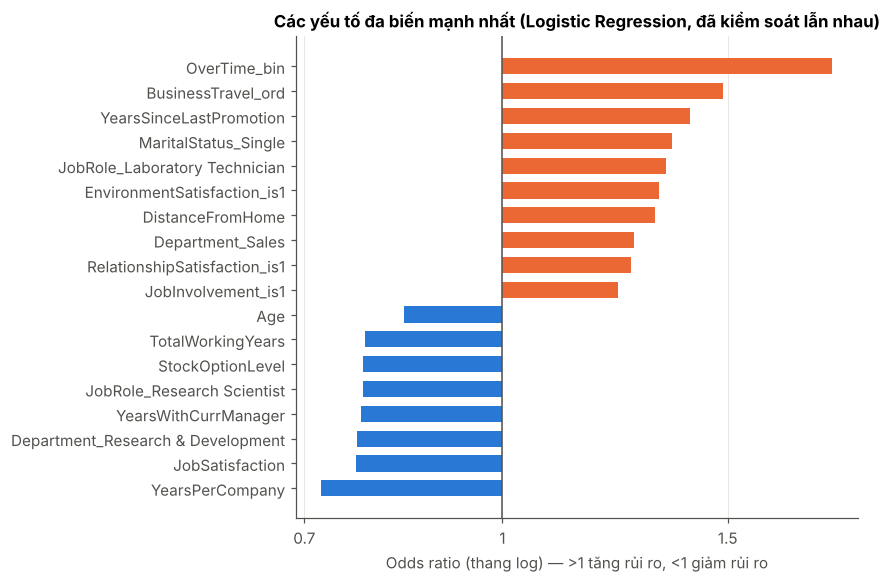

OverTime_bin                         1.81
BusinessTravel_ord                   1.49
YearsSinceLastPromotion              1.40
MaritalStatus_Single                 1.36
JobRole_Laboratory Technician        1.34
EnvironmentSatisfaction_is1          1.33
DistanceFromHome                     1.32
Department_Sales                     1.27
RelationshipSatisfaction_is1         1.26
JobInvolvement_is1                   1.23
Age                                  0.84
TotalWorkingYears                    0.78
StockOptionLevel                     0.78
YearsWithCurrManager                 0.78
JobRole_Research Scientist           0.78
JobSatisfaction                      0.77
Department_Research & Development    0.77
YearsPerCompany                      0.72


In [27]:
# 3.10d Diễn giải Logistic Regression: odds ratio cho mỗi +1 độ lệch chuẩn (biến số) hoặc so với nhóm tham chiếu (one-hot)
lr = models["Logistic Regression"]
feat = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=feat)
orr = np.exp(coef).sort_values()
top = pd.concat([orr.head(8), orr.tail(10)])
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(top.index, top.values - 1, left=1, color=[C_LEAVE if v > 1 else C_STAY for v in top.values], height=0.65)
ax.axvline(1, color=C_INK, lw=1); ax.set_xscale("log")
ax.xaxis.set_major_locator(mtick.FixedLocator([0.4, 0.5, 0.7, 1, 1.5, 2, 2.5]))
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Odds ratio (thang log) — >1 tăng rủi ro, <1 giảm rủi ro"); ax.grid(axis="y", visible=False)
ax.set_title("Các yếu tố đa biến mạnh nhất (Logistic Regression, đã kiểm soát lẫn nhau)")
save(fig, "fig14_odds")
print(top.round(2).sort_values(ascending=False).to_string())

In [28]:
# 3.10d2 Kiểm chứng hệ số: VIF (đa cộng tuyến) và Logit KHÔNG phạt (statsmodels) để có KTC 95% và p-value cho odds ratio
pre_inf = make_pre(numeric, nominal)
Z = pre_inf.fit_transform(X); Z = Z.toarray() if hasattr(Z, "toarray") else Z
Z = pd.DataFrame(Z, columns=pre_inf.get_feature_names_out(), index=X.index)

# (a) VIF cho các biến số (đã log1p + chuẩn hóa); VIF > 5 là dấu hiệu đa cộng tuyến đáng lo, > 10 là nghiêm trọng
num_cols_inf = [c for c in Z.columns if c in numeric]
Zn = sm.add_constant(Z[num_cols_inf])
vif = pd.Series([variance_inflation_factor(Zn.values, i) for i in range(1, Zn.shape[1])], index=num_cols_inf).sort_values(ascending=False)
print("VIF cao nhất:"); print(vif.head(10).round(2).to_string())

# (b) Logit không phạt trên toàn bộ dữ liệu (mục đích suy diễn, không phải dự báo)
logit = sm.Logit(y.values, sm.add_constant(Z)).fit(method="bfgs", maxiter=2000, disp=0)
ci = logit.conf_int()
or_tbl = pd.DataFrame({"OR": np.exp(logit.params), "KTC 2.5%": np.exp(ci[0]), "KTC 97.5%": np.exp(ci[1]),
                       "p": logit.pvalues}).drop("const")
key = ["OverTime_bin", "YearsSinceLastPromotion", "JobLevel", "MonthlyIncome", "StockOptionLevel", "YearsAtCompany",
       "YearsInCurrentRole", "YearsWithCurrManager", "TotalWorkingYears", "BusinessTravel_ord", "DistanceFromHome",
       "JobInvolvement", "EnvironmentSatisfaction", "JobSatisfaction", "EnvironmentSatisfaction_is1", "JobInvolvement_is1",
       "WorkLifeBalance_is1", "JobRole_Laboratory Technician", "JobRole_Sales Representative", "NumCompaniesWorked"]
# p-value đọc theo cách thông thường của Kinh tế lượng (α = 0,05), không hiệu chỉnh đa kiểm định
print("\nOdds ratio (Logit không phạt, mỗi +1 độ lệch chuẩn):")
print(or_tbl.loc[[k for k in key if k in or_tbl.index]].round(3).to_string())

VIF cao nhất:
YearsPerCompany            87.85
TotalWorkingYears          70.17
NumCompaniesWorked         48.70
MonthlyIncome              41.17
JobLevel                   36.86
YearsSinceLastPromotion    10.15
YearsAtCompany              8.59
PromotionStagnation         7.53
RelPayInLevel               6.02
YearsInCurrentRole          3.65



Odds ratio (Logit không phạt, mỗi +1 độ lệch chuẩn):
                                   OR  KTC 2.5%  KTC 97.5%      p
OverTime_bin                    2.586     2.162      3.092  0.000
YearsSinceLastPromotion         3.087     1.623      5.872  0.001
JobLevel                       11.509     1.608     82.395  0.015
MonthlyIncome                   0.072     0.010      0.514  0.009
StockOptionLevel                0.866     0.665      1.127  0.284
YearsAtCompany                  1.273     0.751      2.158  0.370
YearsInCurrentRole              0.682     0.485      0.959  0.028
YearsWithCurrManager            0.661     0.473      0.925  0.016
TotalWorkingYears               0.531     0.132      2.131  0.372
BusinessTravel_ord              1.714     1.418      2.072  0.000
DistanceFromHome                1.580     1.303      1.915  0.000
JobInvolvement                  0.736     0.583      0.928  0.010
EnvironmentSatisfaction         0.796     0.595      1.064  0.124
JobSatisfaction       

In [29]:
# 3.10d3 Mô hình rút gọn để kiểm tra độ vững: bỏ các đặc trưng phái sinh trùng thông tin (YearsPerCompany,
# PromotionStagnation, RelPayInLevel) và TotalWorkingYears (VIF cao nhất) → hệ số còn lại có ổn định không?
drop_red = ["YearsPerCompany", "PromotionStagnation", "RelPayInLevel", "TotalWorkingYears"]
num_red = [c for c in numeric if c not in drop_red]
pre_red = make_pre(num_red, nominal)
Zr = pre_red.fit_transform(X); Zr = Zr.toarray() if hasattr(Zr, "toarray") else Zr
Zr = pd.DataFrame(Zr, columns=pre_red.get_feature_names_out(), index=X.index)
Zrn = sm.add_constant(Zr[[c for c in Zr.columns if c in num_red]])
vif_r = pd.Series([variance_inflation_factor(Zrn.values, i) for i in range(1, Zrn.shape[1])], index=Zrn.columns[1:])
print("VIF lớn nhất sau khi rút gọn:"); print(vif_r.sort_values(ascending=False).head(6).round(2).to_string())
logit_r = sm.Logit(y.values, sm.add_constant(Zr)).fit(method="bfgs", maxiter=2000, disp=0)
ci_r = logit_r.conf_int()
or_r = pd.DataFrame({"OR": np.exp(logit_r.params), "KTC 2.5%": np.exp(ci_r[0]), "KTC 97.5%": np.exp(ci_r[1]),
                     "p": logit_r.pvalues}).drop("const")
print("\nOdds ratio — mô hình rút gọn:")
print(or_r.loc[[k for k in key if k in or_r.index]].round(3).to_string())
print(f"\nAUC trên tập huấn luyện (tham khảo): đầy đủ = {roc_auc_score(y, logit.predict()):.3f} | rút gọn = {roc_auc_score(y, logit_r.predict()):.3f}")

VIF lớn nhất sau khi rút gọn:
MonthlyIncome           7.10
JobLevel                7.03
YearsAtCompany          6.03
YearsInCurrentRole      3.55
YearsWithCurrManager    3.30
JobSatisfaction         2.55



Odds ratio — mô hình rút gọn:
                                   OR  KTC 2.5%  KTC 97.5%      p
OverTime_bin                    2.506     2.104      2.984  0.000
YearsSinceLastPromotion         1.743     1.365      2.226  0.000
JobLevel                        1.359     0.792      2.332  0.266
MonthlyIncome                   0.479     0.295      0.779  0.003
StockOptionLevel                0.890     0.686      1.154  0.380
YearsAtCompany                  1.282     0.833      1.973  0.259
YearsInCurrentRole              0.650     0.469      0.902  0.010
YearsWithCurrManager            0.600     0.435      0.827  0.002
BusinessTravel_ord              1.654     1.373      1.993  0.000
DistanceFromHome                1.516     1.256      1.828  0.000
JobInvolvement                  0.740     0.588      0.931  0.010
EnvironmentSatisfaction         0.837     0.630      1.114  0.223
JobSatisfaction                 0.666     0.497      0.892  0.006
EnvironmentSatisfaction_is1     1.433     1.0

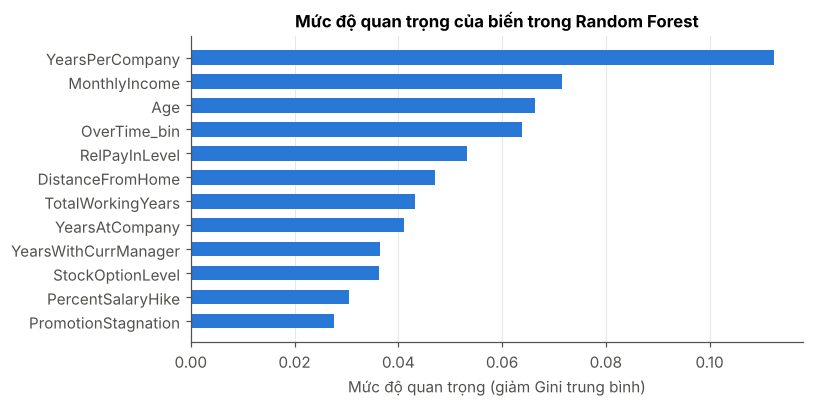

YearsPerCompany         0.1124
MonthlyIncome           0.0716
Age                     0.0664
OverTime_bin            0.0638
RelPayInLevel           0.0532
DistanceFromHome        0.0471
TotalWorkingYears       0.0433
YearsAtCompany          0.0410
YearsWithCurrManager    0.0365
StockOptionLevel        0.0362
PercentSalaryHike       0.0305
PromotionStagnation     0.0275


In [30]:
# 3.10e Mức độ quan trọng của biến trong Random Forest (feature_importances_ — mức giảm Gini trung bình)
rf = models["Random Forest"]
names_rf = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names_rf).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(imp.index[::-1], imp.values[::-1], color=C_STAY, height=0.6)
ax.set_xlabel("Mức độ quan trọng (giảm Gini trung bình)"); ax.grid(axis="y", visible=False)
ax.set_title("Mức độ quan trọng của biến trong Random Forest")
save(fig, "fig15_importance")
print(imp.round(4).to_string())

In [31]:
# 3.10f Kiểm tra đạo đức: bỏ các thuộc tính được bảo vệ, mô hình có kém đi đáng kể không?
protected = ["Gender_bin", "Age", "MaritalStatus"]
num_f = [c for c in numeric if c not in protected]; nom_f = [c for c in nominal if c not in protected]
C_best = models["Logistic Regression"].named_steps["clf"].C          # dùng C đã tinh chỉnh ở 3.10b
lr_fair = Pipeline([("pre", make_pre(num_f, nom_f)),
                    ("clf", LogisticRegression(C=C_best, class_weight="balanced", max_iter=5000))])
auc_fair_cv = cross_val_score(lr_fair, X_tr[num_f + nom_f], y_tr, cv=cv, scoring="roc_auc")
lr_fair.fit(X_tr[num_f + nom_f], y_tr)
auc_fair = roc_auc_score(y_te, lr_fair.predict_proba(X_te[num_f + nom_f])[:, 1])
print(f"Logistic KHÔNG có Gender/Age/MaritalStatus: CV AUC = {auc_fair_cv.mean():.3f} | Test AUC = {auc_fair:.3f}")
print(f"Logistic đầy đủ:                              Test AUC = {roc_auc_score(y_te, lr_pr):.3f}")

# Ma trận nhầm lẫn của mô hình không dùng thuộc tính nhạy cảm, ngưỡng mặc định 0,5
pr_f = lr_fair.predict_proba(X_te[num_f + nom_f])[:, 1]
pred = (pr_f >= 0.5).astype(int)
cmx = confusion_matrix(y_te, pred)
print(pd.DataFrame(cmx, index=["Thực tế: Ở lại", "Thực tế: Nghỉ"], columns=["Dự báo: Ở lại", "Dự báo: Nghỉ"]))
print(classification_report(y_te, pred, target_names=["Ở lại", "Nghỉ"], digits=3))

Logistic KHÔNG có Gender/Age/MaritalStatus: CV AUC = 0.846 | Test AUC = 0.794
Logistic đầy đủ:                              Test AUC = 0.803
                Dự báo: Ở lại  Dự báo: Nghỉ
Thực tế: Ở lại            198            49
Thực tế: Nghỉ              14            33
              precision    recall  f1-score   support

       Ở lại      0.934     0.802     0.863       247
        Nghỉ      0.402     0.702     0.512        47

    accuracy                          0.786       294
   macro avg      0.668     0.752     0.687       294
weighted avg      0.849     0.786     0.807       294



# GIAI ĐOẠN 4 — Đánh giá tác động và khuyến nghị
## 4.1 Ước tính chi phí nghỉ việc
Gallup (McFeely & Wigert, 2019) ước tính chi phí thay thế một nhân viên bằng **0,5–2 lần lương năm**. Dữ liệu không ghi đơn vị tiền tệ nên kết quả trình bày theo *đơn vị tiền tệ của dữ liệu*.

In [32]:
# 4.1 Chi phí nghỉ việc theo 3 kịch bản hệ số thay thế, và đóng góp của từng phân khúc rủi ro
annual = df.MonthlyIncome * 12
leave_cost = pd.DataFrame({f"Hệ số {k}x": [(annual[df.AttritionFlag == 1] * k).sum()] for k in [0.5, 1.0, 2.0]},
                          index=["Tổng chi phí thay thế (237 người)"])
print(leave_cost.map("{:,.0f}".format).to_string())

# Phân khúc ưu tiên: kết hợp OverTime + JobLevel 1 + không có cổ phiếu
seg = {
    "OverTime & JobLevel 1": (df.OverTime == "Yes") & (df.JobLevel == 1),
    "OverTime & JobLevel 1 & Stock 0": (df.OverTime == "Yes") & (df.JobLevel == 1) & (df.StockOptionLevel == 0),
    "Sales Representative": df.JobRole == "Sales Representative",
    "Năm đầu tiên (YearsAtCompany ≤ 1)": df.YearsAtCompany <= 1,
    "OverTime & tuổi ≤ 25": (df.OverTime == "Yes") & (df.Age <= 25),
}
seg_tbl = pd.DataFrame({k: [m.sum(), m.mean(), df.AttritionFlag[m].mean(), df.AttritionFlag[m].sum() / df.AttritionFlag.sum()]
                        for k, m in seg.items()}, index=["n", "% lực lượng", "Tỷ lệ nghỉ", "% tổng số người nghỉ"]).T
seg_tbl["Lift"] = seg_tbl["Tỷ lệ nghỉ"] / base
print(seg_tbl.assign(n=seg_tbl.n.astype(int)).round(3).to_string())
seg_tbl.style.format({"n": "{:.0f}", "% lực lượng": "{:.1%}", "Tỷ lệ nghỉ": "{:.1%}", "% tổng số người nghỉ": "{:.1%}", "Lift": "{:.1f}x"})

                                  Hệ số 0.5x  Hệ số 1.0x  Hệ số 2.0x
Tổng chi phí thay thế (237 người)  6,807,246  13,614,492  27,228,984
                                     n  % lực lượng  Tỷ lệ nghỉ  % tổng số người nghỉ   Lift
OverTime & JobLevel 1              156        0.106       0.526                 0.346  3.260
OverTime & JobLevel 1 & Stock 0     75        0.051       0.667                 0.211  4.135
Sales Representative                83        0.056       0.398                 0.139  2.466
Năm đầu tiên (YearsAtCompany ≤ 1)  215        0.146       0.349                 0.316  2.164
OverTime & tuổi ≤ 25                39        0.027       0.641                 0.105  3.976


,n,% lực lượng,Tỷ lệ nghỉ,% tổng số người nghỉ,Lift
OverTime & JobLevel 1,156,10.6%,52.6%,34.6%,3.3x
OverTime & JobLevel 1 & Stock 0,75,5.1%,66.7%,21.1%,4.1x
Sales Representative,83,5.6%,39.8%,13.9%,2.5x
Năm đầu tiên (YearsAtCompany ≤ 1),215,14.6%,34.9%,31.6%,2.2x
OverTime & tuổi ≤ 25,39,2.7%,64.1%,10.5%,4.0x


In [33]:
# 4.2 Điểm hòa vốn của chương trình giữ chân cho phân khúc "OverTime + JobLevel 1" (tính bằng phép nhân, chia)
# Giả định: chi phí can thiệp = 1 tháng lương cho MỖI nhân viên trong phân khúc;
#           chi phí thay thế 1 người nghỉ = hệ số × lương năm (Gallup: 0,5x–2x)
m_seg = (df.OverTime == "Yes") & (df.JobLevel == 1)
n_seg, n_leave = int(m_seg.sum()), int(df.AttritionFlag[m_seg].sum())
cost_program = df.MonthlyIncome[m_seg].sum() * 1                  # tổng chi phí can thiệp
salary_leavers = df.MonthlyIncome[m_seg & (df.AttritionFlag == 1)].sum() * 12   # tổng lương năm của người nghỉ
print(f"Phân khúc: {n_seg} người, {n_leave} người nghỉ ({n_leave / n_seg:.1%})")
print(f"Chi phí chương trình = {cost_program:,.0f}")
rows = []
for r in [0.5, 1.0, 2.0]:
    loss = salary_leavers * r                                     # chi phí nghỉ việc của phân khúc
    breakeven = cost_program / loss                               # tỷ lệ người nghỉ cần giữ lại để hòa vốn
    rows.append([f"{r}x lương năm", loss, breakeven, breakeven * n_leave])
be_tbl = pd.DataFrame(rows, columns=["Hệ số thay thế", "Chi phí nghỉ việc của phân khúc", "Tỷ lệ cần giữ lại để hòa vốn",
                                     "Số người cần giữ lại"])
print(be_tbl.round(3).to_string(index=False))
be_tbl.style.format({"Chi phí nghỉ việc của phân khúc": "{:,.0f}", "Tỷ lệ cần giữ lại để hòa vốn": "{:.0%}",
                     "Số người cần giữ lại": "{:.1f}"})

Phân khúc: 156 người, 82 người nghỉ (52.6%)
Chi phí chương trình = 437,197
Hệ số thay thế  Chi phí nghỉ việc của phân khúc  Tỷ lệ cần giữ lại để hòa vốn  Số người cần giữ lại
0.5x lương năm                        1286646.0                         0.340                27.863
1.0x lương năm                        2573292.0                         0.170                13.932
2.0x lương năm                        5146584.0                         0.085                 6.966


,Hệ số thay thế,Chi phí nghỉ việc của phân khúc,Tỷ lệ cần giữ lại để hòa vốn,Số người cần giữ lại
0,0.5x lương năm,"1,286,646",34%,27.9
1,1.0x lương năm,"2,573,292",17%,13.9
2,2.0x lương năm,"5,146,584",8%,7.0


## 4.2 Kết luận ngắn
Chi tiết phát hiện, khuyến nghị và giới hạn được trình bày trong **báo cáo PDF**. Tóm tắt:
1. **OverTime là đòn bẩy số 1** và có thể kiểm soát được — đặc biệt nguy hiểm khi kết hợp với cấp bậc 1 và tuổi trẻ.
2. Rủi ro tập trung ở **đầu sự nghiệp / năm đầu tiên** → onboarding và lộ trình 12 tháng đầu.
3. **Trả lương thấp trong cùng cấp** (cấp 1) và **thiếu cổ phiếu** gắn với nghỉ việc; cơ chế đánh giá hiệu suất hiện tại không phân biệt người ở/đi.
4. Mô hình Logistic (AUC ≈ 0,8) giúp HR ưu tiên nhóm nhân viên rủi ro cao mà không cần dùng giới tính, tuổi hay hôn nhân; mô hình chỉ nên dùng làm công cụ hỗ trợ.

*Hết notebook.*